# Comparison of all models on the test split

Every from-scratch model and its scikit-learn counterpart is trained on the training split and evaluated on the test split, with the hyperparameters chosen on the validation split (`sklearn_dt_rf.ipynb` for ID3 and Random Forest, `sklearn_logreg_ann.ipynb` for Logistic Regression and ANN). The notebook also builds the scikit-learn hard VotingClassifier, the comparison table, the report figures and the Kaggle submission file.

In [1]:
import os
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier

NOTEBOOK_DIR = os.path.abspath('.')
SRC_DIR = os.path.abspath(os.path.join(NOTEBOOK_DIR, '..', 'src'))
SPLIT_DIR = os.path.abspath(os.path.join(NOTEBOOK_DIR, '..', 'data'))
FIGURE_DIR = os.path.abspath(os.path.join(NOTEBOOK_DIR, '..', 'doc', 'figures'))
SUBMISSION_DIR = os.path.abspath(os.path.join(NOTEBOOK_DIR, '..', 'submissions'))
os.makedirs(FIGURE_DIR, exist_ok=True)
os.makedirs(SUBMISSION_DIR, exist_ok=True)
sys.path.insert(0, SRC_DIR)

from id3 import ID3
from random_forest import RandomForest
from knn import KNN
from logistic_regression import LogisticRegressionOVR
from neural_network import NeuralNetwork
from ensemble import Ensemble
from evaluate import evaluate

## Load the shared split

In [2]:
LABEL_MAP = {'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}
LABEL_NAMES = ['Dropout', 'Enrolled', 'Graduate']
CLASSES = [0, 1, 2]

train_frame = pd.read_csv(os.path.join(SPLIT_DIR, 'train_preprocessed.csv'))
X_train = train_frame.drop(columns=['Student_ID', 'Target']).to_numpy()
y_train = train_frame['Target'].map(LABEL_MAP).to_numpy()

validation_frame = pd.read_csv(os.path.join(SPLIT_DIR, 'validation_preprocessed.csv'))
X_val = validation_frame.drop(columns=['Student_ID', 'Target']).to_numpy()
y_val = validation_frame['Target'].map(LABEL_MAP).to_numpy()

test_frame = pd.read_csv(os.path.join(SPLIT_DIR, 'test_preprocessed.csv'))
X_test = test_frame.drop(columns=['Student_ID', 'Target']).to_numpy()
y_test = test_frame['Target'].map(LABEL_MAP).to_numpy()

print('train', X_train.shape, 'validation', X_val.shape, 'test', X_test.shape)

train (1857, 211) validation (619, 211) test (620, 211)


## Models

Each algorithm appears twice: from scratch and in scikit-learn, with the same hyperparameters. KNN uses k = 5 with Manhattan distance, the values chosen on the validation split in sklearn_knn.ipynb. The from-scratch ensemble (`src/ensemble.py`) is added in the ensemble section below.

In [3]:
BEST_DEPTH = 12
BEST_TREES = 100

algorithms = ['ID3', 'Random Forest', 'KNN', 'Logistic Regression', 'ANN']

scratch_models = []
scratch_models.append(ID3(max_depth=BEST_DEPTH, random_state=0))
scratch_models.append(RandomForest(n_trees=BEST_TREES, random_state=0))
scratch_models.append(KNN(k=5, metric='manhattan'))
scratch_models.append(LogisticRegressionOVR(learning_rate=0.1, epochs=1000))
scratch_models.append(NeuralNetwork(hidden_layers=(32,), activation='relu', learning_rate=0.01, epochs=200, batch_size=32, random_state=42))

sklearn_models = []
sklearn_models.append(DecisionTreeClassifier(criterion='entropy', max_depth=BEST_DEPTH, random_state=0))
sklearn_models.append(RandomForestClassifier(n_estimators=BEST_TREES, criterion='entropy', random_state=0))
sklearn_models.append(KNeighborsClassifier(n_neighbors=5, metric='manhattan'))
sklearn_models.append(OneVsRestClassifier(LogisticRegression(max_iter=1000, random_state=42)))
sklearn_models.append(MLPClassifier(hidden_layer_sizes=(32,), activation='relu', solver='sgd', learning_rate_init=0.01, batch_size=32, max_iter=200, random_state=42))

## scikit-learn ensemble

The scikit-learn counterpart of the ensemble is a hard VotingClassifier over the five scikit-learn models: each model votes for one class and the majority wins.

The from-scratch counterpart is `Ensemble` in `src/ensemble.py`. It combines the five from-scratch models in the same way: each model votes for one class and the majority wins. When two classes tie, the smaller class label wins, which is also what `VotingClassifier` does. The ensemble trains its own copy of every member, so its fit time is the sum of the five fit times.

In [4]:
voting_members = []
voting_members.append(('dt', DecisionTreeClassifier(criterion='entropy', max_depth=BEST_DEPTH, random_state=0)))
voting_members.append(('rf', RandomForestClassifier(n_estimators=BEST_TREES, criterion='entropy', random_state=0)))
voting_members.append(('knn', KNeighborsClassifier(n_neighbors=5, metric='manhattan')))
voting_members.append(('lr', OneVsRestClassifier(LogisticRegression(max_iter=1000, random_state=42))))
voting_members.append(('ann', MLPClassifier(hidden_layer_sizes=(32,), activation='relu', solver='sgd', learning_rate_init=0.01, batch_size=32, max_iter=200, random_state=42)))

algorithms.append('Ensemble')
ensemble_members = []
ensemble_members.append(ID3(max_depth=BEST_DEPTH, random_state=0))
ensemble_members.append(RandomForest(n_trees=BEST_TREES, random_state=0))
ensemble_members.append(KNN(k=5, metric='manhattan'))
ensemble_members.append(LogisticRegressionOVR(learning_rate=0.1, epochs=1000))
ensemble_members.append(NeuralNetwork(hidden_layers=(32,), activation='relu', learning_rate=0.01, epochs=200, batch_size=32, random_state=42))

scratch_models.append(Ensemble(ensemble_members))
sklearn_models.append(VotingClassifier(estimators=voting_members, voting='hard'))

## Train and evaluate

Each model is trained on the training split. Training time and inference time on the test split are measured with `time.perf_counter`. The validation macro F1 is also recorded, and it is used only to choose the model for the Kaggle submission.

In [5]:
rows = []
test_results = {}
trained = {}

for i in range(len(algorithms)):
    for family in ['scratch', 'sklearn']:
        if family == 'scratch':
            model = scratch_models[i]
        else:
            model = sklearn_models[i]
        if model is None:
            continue

        start = time.perf_counter()
        model.fit(X_train, y_train)
        fit_seconds = time.perf_counter() - start

        start = time.perf_counter()
        test_predictions = model.predict(X_test)
        inference_seconds = time.perf_counter() - start

        results = evaluate(y_test, test_predictions, fit_seconds, inference_seconds, CLASSES)
        validation_results = evaluate(y_val, model.predict(X_val), 0, 0, CLASSES)

        name = algorithms[i] + ' (' + family + ')'
        test_results[name] = results
        trained[name] = model

        row = {}
        row['model'] = name
        row['accuracy'] = round(results['accuracy'], 4)
        row['macro_f1'] = round(results['macro_f1'], 4)
        for c in range(len(CLASSES)):
            row['f1_' + LABEL_NAMES[c]] = round(results['per_class'][c]['f1'], 4)
        row['fit_s'] = round(results['fit_seconds'], 2)
        row['infer_s'] = round(results['inference_seconds'], 3)
        row['validation_macro_f1'] = round(validation_results['macro_f1'], 4)
        rows.append(row)
        print('done:', name)

table = pd.DataFrame(rows)
table

done: ID3 (scratch)
done: ID3 (sklearn)
done: Random Forest (scratch)
done: Random Forest (sklearn)
done: KNN (scratch)
done: KNN (sklearn)
done: Logistic Regression (scratch)
done: Logistic Regression (sklearn)
done: ANN (scratch)


c:\Users\IDEAPAD\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


done: ANN (sklearn)
done: Ensemble (scratch)


c:\Users\IDEAPAD\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


done: Ensemble (sklearn)


,model,accuracy,macro_f1,f1_Dropout,f1_Enrolled,f1_Graduate,fit_s,infer_s,validation_macro_f1
0,ID3 (scratch),0.7032,0.6175,0.7427,0.3191,0.7906,2.49,0.005,0.6314
1,ID3 (sklearn),0.7000,0.6224,0.7327,0.3469,0.7875,0.07,0.000,0.6208
2,Random Forest (scratch),0.7661,0.6453,0.7990,0.2917,0.8453,40.67,0.788,0.6733
3,Random Forest (sklearn),0.7726,0.6713,0.8020,0.3660,0.8459,0.38,0.013,0.6719
4,KNN (scratch),0.7177,0.6378,0.7192,0.3756,0.8187,0.00,1.519,0.6161
5,KNN (sklearn),0.7177,0.6378,0.7192,0.3756,0.8187,0.00,0.122,0.6161
6,Logistic Regression (scratch),0.7661,0.6754,0.7949,0.3860,0.8454,1.02,0.019,0.6830
7,Logistic Regression (sklearn),0.7855,0.7144,0.8052,0.4809,0.8571,0.13,0.001,0.6990
8,ANN (scratch),0.7661,0.7014,0.8010,0.4631,0.8400,1.43,0.000,0.6980
9,ANN (sklearn),0.7516,0.6887,0.7647,0.4677,0.8336,3.16,0.003,0.6471


## Per-class precision and recall on the test split

In [11]:
for name in test_results:
    print(name)
    results = test_results[name]
    for c in range(len(CLASSES)):
        scores = results['per_class'][c]
        print('  ', LABEL_NAMES[c], 'precision', round(scores['precision'], 4), 'recall', round(scores['recall'], 4), 'f1', round(scores['f1'], 4))

ID3 (scratch)
   Dropout precision 0.7183 recall 0.7688 f1 0.7427
   Enrolled precision 0.3896 recall 0.2703 f1 0.3191
   Graduate precision 0.7667 recall 0.8161 f1 0.7906
ID3 (sklearn)
   Dropout precision 0.722 recall 0.7437 f1 0.7327
   Enrolled precision 0.4 recall 0.3063 f1 0.3469
   Graduate precision 0.7636 recall 0.8129 f1 0.7875
Random Forest (scratch)
   Dropout precision 0.799 recall 0.799 f1 0.799
   Enrolled precision 0.6364 recall 0.1892 f1 0.2917
   Graduate precision 0.7603 recall 0.9516 f1 0.8453
Random Forest (sklearn)
   Dropout precision 0.8 recall 0.804 f1 0.802
   Enrolled precision 0.6667 recall 0.2523 f1 0.366
   Graduate precision 0.7698 recall 0.9387 f1 0.8459
KNN (scratch)
   Dropout precision 0.7527 recall 0.6884 f1 0.7192
   Enrolled precision 0.4302 recall 0.3333 f1 0.3756
   Graduate precision 0.7699 recall 0.8742 f1 0.8187
KNN (sklearn)
   Dropout precision 0.7527 recall 0.6884 f1 0.7192
   Enrolled precision 0.4302 recall 0.3333 f1 0.3756
   Graduate pr

## Save and load the ensemble

Spec point 9 for the from-scratch ensemble. The saved file contains the five trained members. The loaded ensemble must give the same predictions on the test split.

In [7]:
MODEL_DIR = os.path.abspath(os.path.join(NOTEBOOK_DIR, '..', 'models'))
os.makedirs(MODEL_DIR, exist_ok=True)

ensemble_path = os.path.join(MODEL_DIR, 'ensemble_scratch.pkl')
trained['Ensemble (scratch)'].save(ensemble_path)
loaded_ensemble = Ensemble.load(ensemble_path)

before = trained['Ensemble (scratch)'].predict(X_test)
after = loaded_ensemble.predict(X_test)
print('ensemble: identical predictions after load:', bool(np.array_equal(before, after)))

ensemble: identical predictions after load: True


## Figure: confusion matrices

Rows are the true classes and columns are the predicted classes. The top row shows the from-scratch models and the bottom row their scikit-learn counterparts.

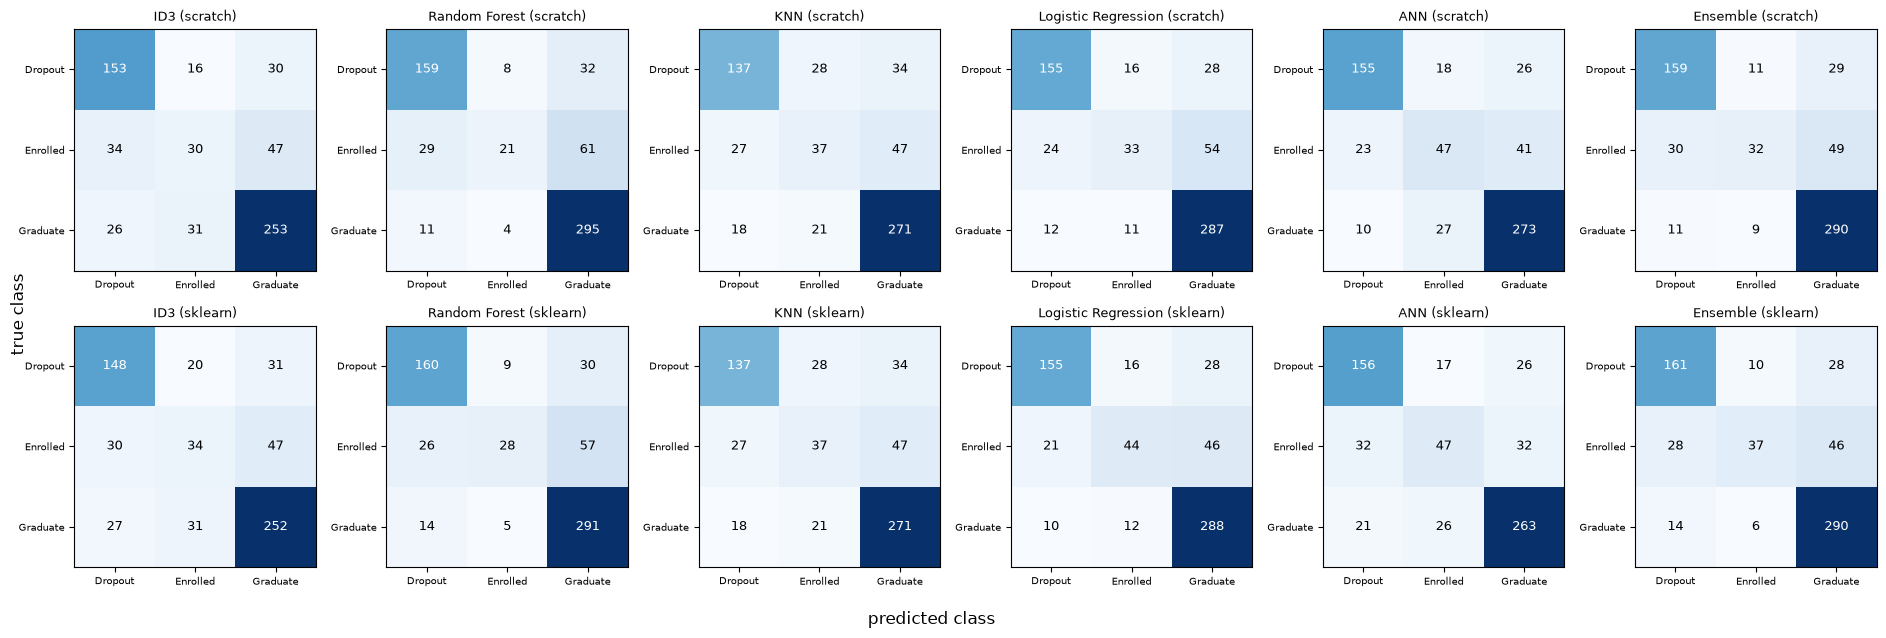

In [8]:
names = list(test_results.keys())
number_of_columns = len(algorithms)
figure, axes = plt.subplots(2, number_of_columns, figsize=(3.2 * number_of_columns, 6.4))

for i in range(len(algorithms)):
    for r in range(2):
        axis = axes[r, i]
        if r == 0:
            name = algorithms[i] + ' (scratch)'
        else:
            name = algorithms[i] + ' (sklearn)'
        if name not in test_results:
            axis.axis('off')
            axis.set_title(name + ': not yet', fontsize=9)
            continue
        matrix = test_results[name]['confusion_matrix']
        axis.imshow(matrix, cmap='Blues')
        for row in range(3):
            for column in range(3):
                value = matrix[row, column]
                color = 'black'
                if value > matrix.max() / 2:
                    color = 'white'
                axis.text(column, row, str(value), ha='center', va='center', color=color, fontsize=9)
        axis.set_xticks([0, 1, 2])
        axis.set_yticks([0, 1, 2])
        axis.set_xticklabels(LABEL_NAMES, fontsize=7)
        axis.set_yticklabels(LABEL_NAMES, fontsize=7)
        axis.set_title(name, fontsize=9)

figure.supxlabel('predicted class')
figure.supylabel('true class')
figure.tight_layout()
figure.savefig(os.path.join(FIGURE_DIR, 'confusion_matrices.png'), dpi=150)
plt.show()

## Figure: accuracy and macro F1

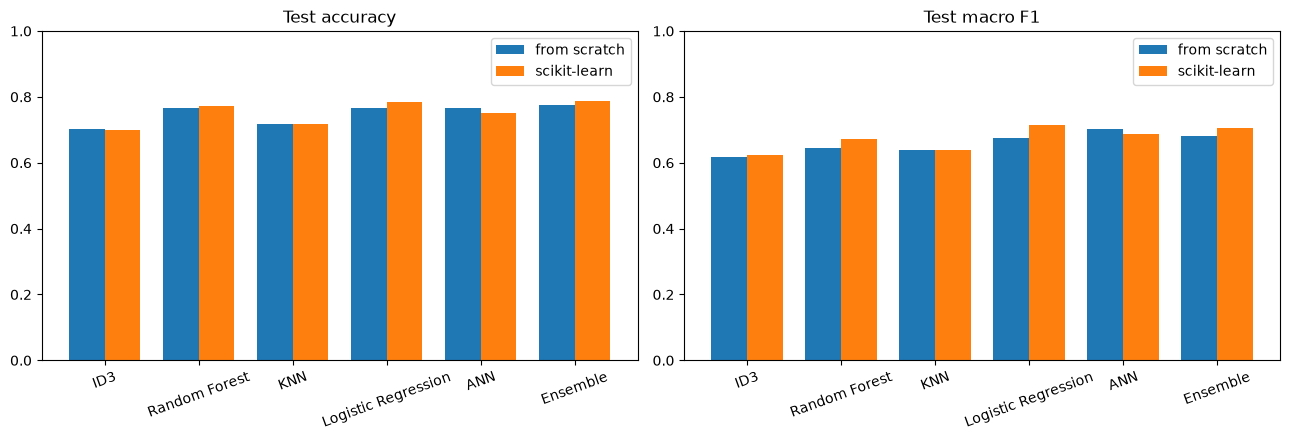

In [12]:
scratch_accuracy = []
sklearn_accuracy = []
scratch_f1 = []
sklearn_f1 = []

for i in range(len(algorithms)):
    scratch_name = algorithms[i] + ' (scratch)'
    sklearn_name = algorithms[i] + ' (sklearn)'
    if scratch_name in test_results:
        scratch_accuracy.append(test_results[scratch_name]['accuracy'])
        scratch_f1.append(test_results[scratch_name]['macro_f1'])
    else:
        scratch_accuracy.append(0)
        scratch_f1.append(0)
    sklearn_accuracy.append(test_results[sklearn_name]['accuracy'])
    sklearn_f1.append(test_results[sklearn_name]['macro_f1'])

positions = np.arange(len(algorithms))
width = 0.38
figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(positions - width / 2, scratch_accuracy, width, label='from scratch')
axes[0].bar(positions + width / 2, sklearn_accuracy, width, label='scikit-learn')
axes[0].set_title('Test accuracy')

axes[1].bar(positions - width / 2, scratch_f1, width, label='from scratch')
axes[1].bar(positions + width / 2, sklearn_f1, width, label='scikit-learn')
axes[1].set_title('Test macro F1')

for axis in axes:
    axis.set_xticks(positions)
    axis.set_xticklabels(algorithms, rotation=20)
    axis.set_ylim(0, 1)
    axis.legend()

figure.tight_layout()
figure.savefig(os.path.join(FIGURE_DIR, 'accuracy_macro_f1.png'), dpi=150)
plt.show()

## Kaggle submission

The from-scratch model with the highest validation macro F1 predicts the Kaggle test set. Its predictions are mapped back to the label names.

In [13]:
best_name = ''
best_score = -1
for row in rows:
    if row['model'].endswith('(scratch)') and row['validation_macro_f1'] > best_score:
        best_score = row['validation_macro_f1']
        best_name = row['model']
print('submitting:', best_name, 'validation macro F1', best_score)

kaggle_frame = pd.read_csv(os.path.join(SPLIT_DIR, 'kaggle_test_preprocessed.csv'))
X_kaggle = kaggle_frame.drop(columns=['Student_ID']).to_numpy()
kaggle_predictions = trained[best_name].predict(X_kaggle)

labels = []
for prediction in kaggle_predictions:
    labels.append(LABEL_NAMES[int(prediction)])

submission = pd.DataFrame({'Student_ID': kaggle_frame['Student_ID'], 'Target': labels})
submission.to_csv(os.path.join(SUBMISSION_DIR, 'submission.csv'), index=False)
print(submission.shape)
print(submission['Target'].value_counts())

submitting: ANN (scratch) validation macro F1 0.698
(1328, 2)
Target
Graduate    714
Dropout     401
Enrolled    213
Name: count, dtype: int64
